In [1]:
import pandas as pd
import numpy  as np
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual dos gráficos
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

**import pandas as pd**: Importa o Pandas para manipular tabelas de dados (DataFrames).

------------------------------------

**import numpy as np**: Importa o NumPy para operações matemáticas avançadas.

------------------------------------

**import scipy.stats as stats**: Importa o módulo de estatística do SciPy (usado para rodar testes como Teste T, Mann-Whitney, etc.).

------------------------------------

**import statsmodels.api as sm** e **from statsmodels.formula.api import ols**: Importam ferramentas do Statsmodels para rodar modelos de regressão e análises de variância (ANOVA).

------------------------------------

**import matplotlib.pyplot as plt** e **import seaborn as sns**: Importam as bibliotecas responsáveis por gerar os gráficos estatísticos.

------------------------------------

In [3]:
df = pd.read_table('dados_glicemia.txt')

display(df.head())

df.info()

display(df.describe())

,"Id,Nome,Data_Nascimento,Remedio_1,Remedio_2,Data_Inicio,Data_Fim,Glicemia_Inicial,Glicemia_Final,Dieta"
0,"P0001,Lucas Rocha Teixeira,01/12/1985,NÃ£o,Sim..."
1,"P0002,Leandro Ramos Mendes,11/07/1961,Sim,NÃ£o..."
2,"P0003,Yasmin Ramos Rocha,10/11/1958,Sim,NÃ£o,1..."
3,"P0004, Carlos Dias Ferreira ,04/01/1990,NÃ£o..."
4,"p0005,AntÃ´nio Santos Andrade,12/08/1972,Sim,N..."


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 1 columns):
 #   Column                                                                                                  Non-Null Count  Dtype 
---  ------                                                                                                  --------------  ----- 
 0   Id,Nome,Data_Nascimento,Remedio_1,Remedio_2,Data_Inicio,Data_Fim,Glicemia_Inicial,Glicemia_Final,Dieta  500 non-null    object
dtypes: object(1)
memory usage: 4.0+ KB


,"Id,Nome,Data_Nascimento,Remedio_1,Remedio_2,Data_Inicio,Data_Fim,Glicemia_Inicial,Glicemia_Final,Dieta"
count,500
unique,500
top,"P0001,Lucas Rocha Teixeira,01/12/1985,NÃ£o,Sim..."
freq,1


**pd.read_table("dados_glicemia.table")**: Lê o arquivo de dados e o transforma em uma tabela virtual chamada df.

-------------------------------------

**display(df.head())**: Mostra na tela as primeiras linhas para você conferir os nomes das colunas (ex: glicemia antes, depois, medicamento, dieta).

-------------------------------------

**df.info()**: Mostra a quantidade de linhas, colunas e se há dados faltando (nulos).

-------------------------------------

**df.describe()**: Calcula o resumo estatístico padrão (média, desvio padrão, mínimo, máximo e quartis) de todas as colunas numéricas.

-------------------------------------

# **Análise 1: Efeito do Tratamento na Glicemia**

O objetivo é testar se houve diferença estatística na glicemia dos pacientes antes e depois do tratamento.

Estatística t: 3.9103
Valor-p: 0.00011


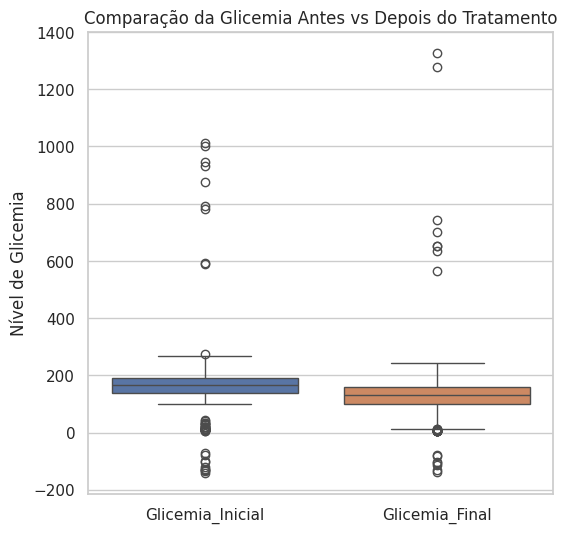

In [10]:
df = pd.read_csv('dados_glicemia.txt')

df['Glicemia_Inicial'] = pd.to_numeric(df['Glicemia_Inicial'], errors='coerce')
df['Glicemia_Final'] = pd.to_numeric(df['Glicemia_Final'], errors='coerce')

df = df.dropna(subset=['Glicemia_Inicial', 'Glicemia_Final'])

df['reducao_glicemia'] = df['Glicemia_Inicial'] - df['Glicemia_Final']

stat_t, p_valor_t = stats.ttest_rel(df['Glicemia_Inicial'], df['Glicemia_Final'])

print(f'Estatística t: {stat_t:.4f}')
print(f'Valor-p: {p_valor_t:.5f}')

plt.figure(figsize=(6, 6))
sns.boxplot(data=df[['Glicemia_Inicial', 'Glicemia_Final']])
plt.title('Comparação da Glicemia Antes vs Depois do Tratamento')
plt.ylabel('Nível de Glicemia')
plt.show()

**df = pd.read_csv('dados_glicemia.txt')**: Carrega o arquivo de texto com os dados para dentro de uma tabela virtual chamada **df**

-----------------------------

**df['Glicemia_Inicial'] = pd.to_numeric(df['Glicemia_Inicial'], errors='coerce')...**: Converte as colunas de glicemia para formato numérico e transforma eventuais erros ou textos corrompidos em valores nulos.

-----------------------------

**df = df.dropna(subset=['Glicemia_Inicial', 'Glicemia_Final'])**: Remove da tabela as linhas que possuem dados faltando.

-----------------------------

**df['reducao_glicemia'] = df['Glicemia_Inicial'] - df['Glicemia_Final']**: Cria uma nova coluna calculando a queda da glicemia (inicial menos final) para cada paciente.

-----------------------------

**stat_t, p_valor_t = stats.ttest_rel(df['Glicemia_Inicial'], df['Glicemia_Final'])**: Executa o Teste T emparelhado para comparar a glicemia antes e depois nos mesmos pacientes.

-----------------------------

**print(f'Estatística t: {stat_t:.4f}')
print(f'Valor-p: {p_valor_t:.5f}')**: Mostra na tela o resultado numérico e o valor-p do teste estatístico.

-----------------------------

**plt.figure(figsize=(6, 6))**: Define o tamanho do gráfico que será desenhado.

-----------------------------

**sns.boxplot(data=df[['Glicemia_Inicial', 'Glicemia_Final']])**: Cria o gráfico de caixa (boxplot) comparando as duas colunas de glicemia.

-----------------------------

**plt.title('Comparação da Glicemia Antes vs Depois do Tratamento')
plt.ylabel('Nível de Glicemia')**: Adiciona o título e o nome do eixo vertical do gráfico.

-----------------------------

**plt.show()**: Exibe o gráfico pronto na tela.

-----------------------------

# **Análise 2: Comparação entre os Medicamentos**

O objetivo é verificar se o Medicamento 1 reduz mais a glicemia do que o Medicamento 2 (grupos independentes).

Estatística t: -1.3273
Valor-p: 1.85200e-01


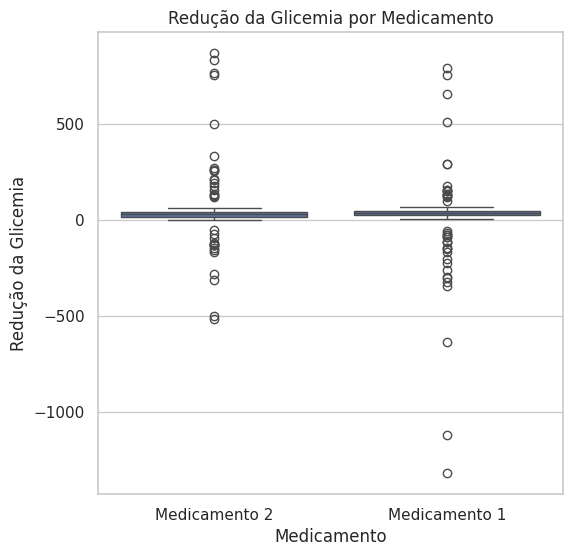

In [12]:
def definir_medicamento(row):
    if row['Remedio_1'] == 'Sim':
        return 'Medicamento 1'
    elif row['Remedio_2'] == 'Sim':
        return 'Medicamento 2'
    return 'Nenhum'

df['medicamento'] = df.apply(definir_medicamento, axis=1)

g1 = df[df['medicamento'] == 'Medicamento 1']['reducao_glicemia']
g2 = df[df['medicamento'] == 'Medicamento 2']['reducao_glicemia']

stat_t, p_valor_t = stats.ttest_ind(g1, g2, nan_policy='omit')

print(f'Estatística t: {stat_t:.4f}')
print(f'Valor-p: {p_valor_t:.5e}')

plt.figure(figsize=(6, 6))
sns.boxplot(x='medicamento', y='reducao_glicemia', data=df[df['medicamento'].isin(['Medicamento 1', 'Medicamento 2'])])
plt.title('Redução da Glicemia por Medicamento')
plt.xlabel('Medicamento')
plt.ylabel('Redução da Glicemia')
plt.show()

**def definir_medicamento(row)**: Cria uma função de lógica condicional. Para cada linha **(row)**, se **Remedio_1** for igual a '**Sim**', ela classifica o paciente como '**Medicamento 1**'. Se **Remedio_2** for '**Sim**', classifica como '**Medicamento 2**'. Se nenhum for '**Sim**', classifica como '**Nenhum**'.

--------------------------------------

**df['medicamento'] = df.apply(..., axis=1)**: O **.apply(..., axis=1)** varre todas as linhas da tabela e cria a nova coluna chamada medicamento.

--------------------------------------

**g1 = ... e g2 = ...**: Filtra as séries numéricas de redução de glicemia separando os pacientes do Medicamento 1 dos do Medicamento 2.

--------------------------------------

**stats.ttest_ind(g1, g2, nan_policy='omit')**: Realiza o Teste T para grupos independentes. O parâmetro nan_policy='omit' ignora de forma segura quaisquer valores ausentes (**NaN**) sem quebrar a execução.

--------------------------------------

**stats.ttest_ind(g1, g2, nan_policy='omit')**: Realiza o Teste T para grupos independentes. O **parâmetro nan_policy='omit'** ignora de forma segura quaisquer valores ausentes (**NaN**) sem quebrar a execução.

--------------------------------------

**data=df[df['medicamento'].isin([...])]**: Filtra a base que alimenta o **sns.boxplot** para desenhar no gráfico apenas as caixas dos pacientes que usaram algum dos dois remédios, omitindo quem não tomou nenhum.

--------------------------------------

# **Análise 3: Influência da Dieta**

Investiga se seguir a dieta contribui para reduzir a glicemia, isolando o efeito dos medicamentos através de uma ANOVA (Análise de Variância).

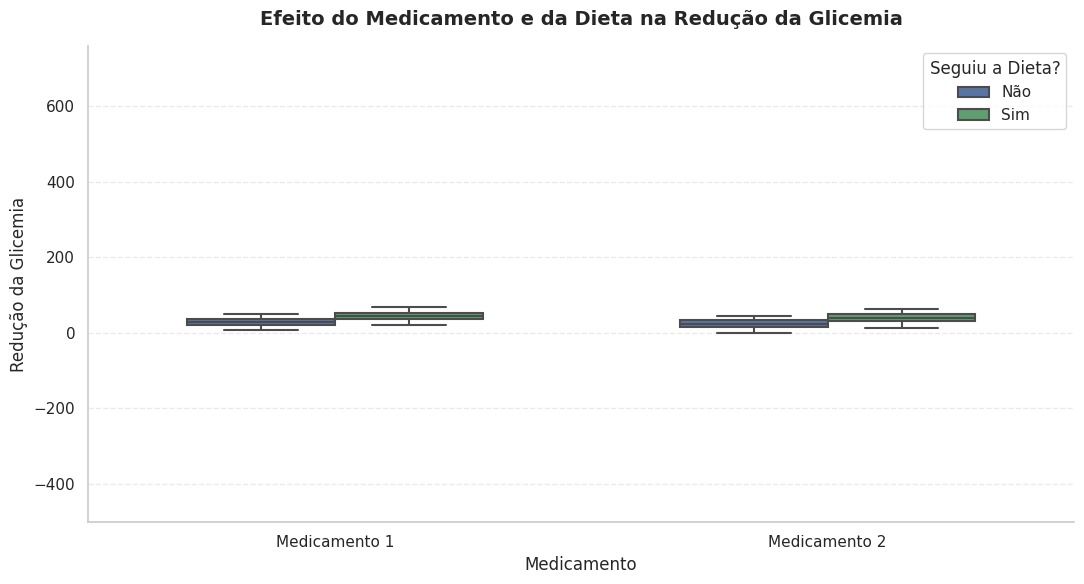

In [18]:
df['Dieta'] = (
    df['Dieta']
    .astype(str)
    .str.strip()
    .str.normalize('NFKD')
    .str.encode('ascii', errors='ignore')
    .str.decode('utf-8')
    .str.lower()
)

df['Dieta'] = df['Dieta'].replace({
    'sim': 'Sim',
    's': 'Sim',
    '1': 'Sim',
    'yes': 'Sim',
    'nao': 'Não',
    'n': 'Não',
    '0': 'Não',
    'no': 'Não',
    'nafo': 'Não'
})

df_filtrado = df[
    df['medicamento'].isin(['Medicamento 1', 'Medicamento 2'])
].copy()

df_filtrado['reducao_glicemia'] = pd.to_numeric(
    df_filtrado['reducao_glicemia'],
    errors='coerce'
)

df_filtrado = df_filtrado.dropna(
    subset=['Dieta', 'medicamento', 'reducao_glicemia']
)

limite_inferior = df_filtrado['reducao_glicemia'].quantile(0.01)
limite_superior = df_filtrado['reducao_glicemia'].quantile(0.99)

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_filtrado,
    x='medicamento',
    y='reducao_glicemia',
    hue='Dieta',
    order=['Medicamento 1', 'Medicamento 2'],
    hue_order=['Não', 'Sim'],
    palette={
        'Não': '#4C72B0',
        'Sim': '#55A868'
    },
    showfliers=False,
    width=0.6,
    linewidth=1.5
)

plt.title(
    'Efeito do Medicamento e da Dieta na Redução da Glicemia',
    fontsize=14,
    fontweight='bold',
    pad=15
)

plt.xlabel('Medicamento', fontsize=12)
plt.ylabel('Redução da Glicemia', fontsize=12)

plt.ylim(limite_inferior, limite_superior)

plt.legend(
    title='Seguiu a Dieta?',
    loc='best',
    frameon=True
)

plt.grid(axis='y', linestyle='--', alpha=0.4)

sns.despine()

plt.tight_layout()
plt.show()


**df['Dieta'] = (
    df['Dieta']...
)**: Transforma a coluna Dieta em texto **(astype(str))**, remove espaços vazios extras nas pontas **(str.strip())**, remove acentos e caracteres especiais (normalize, encode e decode) e converte tudo para letras minúsculas **(.str.lower())**. Isso evita que variações como " **Sim** ", "**SIM**" ou "**Não**" quebrem a análise.

----------------------------------------

**df['Dieta'] = df['Dieta'].replace({
    'sim': 'Sim',
    's': 'Sim',
    '1': 'Sim',
    'yes': 'Sim',
    'nao': 'Não',
    'n': 'Não',
    '0': 'Não',
    'no': 'Não',
    'nafo': 'Não'
})**: Padroniza todas as diferentes formas de escrita que significam "Sim" ou "Não" em um formato unificado e limpo (**'Sim' ou 'Não'**).

----------------------------------------

**df_filtrado = df[
    df['medicamento'].isin(['Medicamento 1', 'Medicamento 2'])
].copy()**: Cria uma nova tabela temporária chamada **df_filtrado** contendo apenas os pacientes que usaram o **Medicamento 1** ou o **Medicamento 2**, isolando os dados de quem não tomou nenhum remédio.

----------------------------------------

**df_filtrado['reducao_glicemia'] = pd.to_numeric(
    df_filtrado['reducao_glicemia'],
    errors='coerce'
)**: Garante que a coluna de redução da glicemia seja tratada como número. Caso haja algum texto ou caractere inválido, ele converte para valor nulo (**NaN**) em vez de travar o código.

----------------------------------------

**df_filtrado = df_filtrado.dropna(
    subset=['Dieta', 'medicamento', 'reducao_glicemia']
)**: Remove da tabela todas as linhas que tenham valores ausentes (**NaN**) nas colunas essenciais (**Dieta, medicamento ou reducao_glicemia**).

----------------------------------------

**limite_inferior = df_filtrado['reducao_glicemia'].quantile(0.01))...**: Calcula os limites estatísticos de 1% e 99% dos dados. Isso serve para cortar valores absurdos ou erros extremos de digitação na hora de exibir o gráfico, mantendo o foco na distribuição principal.

----------------------------------------

**plt.figure(figsize=(11, 6))**: Cria a tela em branco do gráfico, definindo o tamanho dela em 11 polegadas de largura por 6 de altura.

----------------------------------------

**sns.boxplot(
    data=df_filtrado,
    x='medicamento',
    y='reducao_glicemia',
    hue='Dieta',
    order=['Medicamento 1', 'Medicamento 2'],
    hue_order=['Não', 'Sim'],
    palette={
        'Não': '#4C72B0',
        'Sim': '#55A868'
    },
    showfliers=False,
    width=0.6,
    linewidth=1.5
)**:
*   **x e y**: Coloca os medicamentos no eixo horizontal e a redução da glicemia no vertical.
*   **hue='Dieta**': Divide as caixas por cores baseadas em quem fez ou não dieta.
*   **order e hue_order**: Forçam a ordem correta de exibição das categorias.
*   **palette**: Define as cores personalizadas (azul para Não, verde para Sim).
*   **showfliers=False**: Oculta os pontos extremos (outliers) para deixar o visual mais limpo.
*   **width e linewidth**: Ajustam a largura e a grossura das linhas das caixas.

----------------------------------------

**plt.title(
    'Efeito do Medicamento e da Dieta na Redução da Glicemia',
    fontsize=14,
    fontweight='bold',
    pad=15
)**: Adiciona o título principal do gráfico, definindo o tamanho da fonte (**14**), deixando em negrito (**bold**) e ajustando o espaçamento superior (**pad=15**).

----------------------------------------

**plt.xlabel('Medicamento', fontsize=12)
plt.ylabel('Redução da Glicemia', fontsize=12)**: Dá nome aos eixos X (**Medicamento**) e Y (**Redução da Glicemia**), configurando o tamanho da letra para 12.

----------------------------------------

**plt.ylim(limite_inferior, limite_superior)**: Aplica os limites calculados anteriormente (1% e 99%) no eixo vertical, cortando exageros visuais.

----------------------------------------

**plt.legend(
    title='Seguiu a Dieta?',
    loc='best',
    frameon=True
)**: Cria a legenda lateral com o título "Seguiu a Dieta?", posicionando-a automaticamente no melhor local possível (best) com uma moldura ao redor (frameon=True).

----------------------------------------

**plt.grid(axis='y', linestyle='--', alpha=0.4)**: O que faz: Insere linhas de grade tracejadas (**--**) e discretas (**alpha=0.4**) apenas no eixo vertical (**axis='y'**) para facilitar a leitura dos valores.

----------------------------------------

**sns.despine()**: Remove as bordas superior e direita do gráfico, dando um visual mais moderno e profissional (estilo clean).

----------------------------------------

**plt.tight_layout()
plt.show()**: O **tight_layout()** ajusta automaticamente os espaçamentos para que nenhum texto seja cortado, e o **plt.show()** renderiza e exibe o gráfico finalizado na sua tela do Colab!

----------------------------------------

# **Análise 4: Confiabilidade dos Resultados sobre a Dieta**

Calcula o Intervalo de Confiança de 95% para a diferença da dieta e analisa a força estatística.

In [19]:
dieta_sim = df_filtrado[df_filtrado['Dieta'] == 'Sim']['reducao_glicemia']
dieta_nao = df_filtrado[df_filtrado['Dieta'] == 'Não']['reducao_glicemia']

media_sim = dieta_sim.mean()
media_nao = dieta_nao.mean()
diff_medias = media_sim - media_nao

res = stats.ttest_ind(dieta_sim, dieta_nao, nan_policy='omit')
ci = res.confidence_interval(confidence_level=0.95)

print(f'Média com Dieta: {media_sim:.2f}')
print(f'Media sem Dieta: {media_nao:.2f}')
print(f'Diferença das Médias: {diff_medias:.2f}')
print(f'Intevalo de Confiança de 95% para a Diferença: {ci}')

Média com Dieta: 42.46
Media sem Dieta: 23.87
Diferença das Médias: 18.59
Intevalo de Confiança de 95% para a Diferença: ConfidenceInterval(low=np.float64(-15.604913855236077), high=np.float64(52.78335401659871))


**dieta_sim = df_filtrado[df_filtrado['Dieta'] == 'Sim']['reducao_glicemia']
dieta_nao = df_filtrado[df_filtrado['Dieta'] == 'Não']['reducao_glicemia']**: Filtra os dados da tabela limpa (**df_filtrado**) separando a redução de glicemia em dois grupos: quem seguiu a dieta ('**Sim**') e quem não seguiu ('**Não**').

----------------------------------------

**media_sim = dieta_sim.mean()
media_nao = dieta_nao.mean()
diff_medias = media_sim - media_nao**: Calcula a média de redução da glicemia para cada grupo e subtrai a média do grupo sem dieta da do grupo com dieta para sabermos a diferença absoluta.

----------------------------------------

**res = stats.ttest_ind(dieta_sim, dieta_nao, nan_policy='omit')
ci = res.confidence_interval(confidence_level=0.95)**: Executa o **Teste T** independente entre os dois grupos de dieta (**ignorando eventuais valores nulos com nan_policy='omit**') e extrai automaticamente o Intervalo de Confiança de 95% para a diferença entre eles.

----------------------------------------

**print(f'Média com Dieta: {media_sim:.2f}')
print(f'Média sem Dieta: {media_nao:.2f}')
print(f'Diferença das Médias: {diff_medias:.2f}')
print(f'Intervalo de Confiança de 95% para a Diferença: {ci}')**: Imprime todos os resultados no console formatados com duas casas decimais (**:.2f**) para facilitar a leitura no seu relatório.

----------------------------------------